I am going to start by experimenting with pandas


In [1]:
import pandas as pd

df = pd.read_csv("../data/raw/books.csv") # CSV -> DataFrame

In [2]:
#Trying out pandas methods
df.head() # Show the first 5 rows of the DataFrame



,title,category,description,image_url,image_path
0,Soumission,Fiction,"Dans une France assez proche de la nôtre, un h...",https://books.toscrape.com/media/cache/ee/cf/e...,images/soumission_998.jpg
1,Private Paris (Private #10),Fiction,Paris is burning--and only Private's Jack Morg...,https://books.toscrape.com/media/cache/05/87/0...,images/private-paris-private-10_958.jpg
2,"We Love You, Charlie Freeman",Fiction,"The Freeman family--Charles, Laurel, and their...",https://books.toscrape.com/media/cache/87/a2/8...,images/we-love-you-charlie-freeman_954.jpg
3,Thirst,Fiction,"On a searing summer Friday, Eddie Chapman has ...",https://books.toscrape.com/media/cache/8c/54/8...,images/thirst_946.jpg
4,The Murder That Never Was (Forensic Instincts #5),Fiction,"Given the opportunity, would you assume someon...",https://books.toscrape.com/media/cache/29/e0/2...,images/the-murder-that-never-was-forensic-inst...


From df.head() we see that we have the columns we wanted

In [3]:
df.info() # Show information about the DataFrame, including column names, data types, and non-null counts


<class 'pandas.DataFrame'>
RangeIndex: 175 entries, 0 to 174
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   title        175 non-null    str  
 1   category     175 non-null    str  
 2   description  175 non-null    str  
 3   image_url    175 non-null    str  
 4   image_path   175 non-null    str  
dtypes: str(5)
memory usage: 7.0 KB


In [4]:
df.shape # Show the number of rows and columns in the DataFrame


(175, 5)

In [5]:
df["category"].value_counts() # Show the count of unique values in the "category" column


category
Nonfiction    110
Fiction        65
Name: count, dtype: int64

Here we can see that we have all the books we wanted from both categories

In [6]:
df.loc[0, "description"] # Show the description of the first book (row 0)

'Dans une France assez proche de la nôtre, un homme s’engage dans la carrière universitaire. Peu motivé par l’enseignement, il s’attend à une vie ennuyeuse mais calme, protégée des grands drames historiques. Cependant les forces en jeu dans le pays ont fissuré le système politique jusqu’à provoquer son effondrement. Cette implosion sans soubresauts, sans vraie révolution, s Dans une France assez proche de la nôtre, un homme s’engage dans la carrière universitaire. Peu motivé par l’enseignement, il s’attend à une vie ennuyeuse mais calme, protégée des grands drames historiques. Cependant les forces en jeu dans le pays ont fissuré le système politique jusqu’à provoquer son effondrement. Cette implosion sans soubresauts, sans vraie révolution, se développe comme un mauvais rêve.Le talent de l’auteur, sa force visionnaire nous entraînent sur un terrain ambigu et glissant ; son regard sur notre civilisation vieillissante fait coexister dans ce roman les intuitions poétiques, les effets comi

Im going to look for some books that have a description in english to spare my eyes. I am going to start by looking at 5 and see if i notice anything wrong with the data. 

In [7]:
for i in range(11):
    print(df.loc[i, "description"])

Dans une France assez proche de la nôtre, un homme s’engage dans la carrière universitaire. Peu motivé par l’enseignement, il s’attend à une vie ennuyeuse mais calme, protégée des grands drames historiques. Cependant les forces en jeu dans le pays ont fissuré le système politique jusqu’à provoquer son effondrement. Cette implosion sans soubresauts, sans vraie révolution, s Dans une France assez proche de la nôtre, un homme s’engage dans la carrière universitaire. Peu motivé par l’enseignement, il s’attend à une vie ennuyeuse mais calme, protégée des grands drames historiques. Cependant les forces en jeu dans le pays ont fissuré le système politique jusqu’à provoquer son effondrement. Cette implosion sans soubresauts, sans vraie révolution, se développe comme un mauvais rêve.Le talent de l’auteur, sa force visionnaire nous entraînent sur un terrain ambigu et glissant ; son regard sur notre civilisation vieillissante fait coexister dans ce roman les intuitions poétiques, les effets comiq

Seems like it was only the first book that was in french. In that case im going to examine books 2,3,4,5,6

In [8]:
for i in range(1,7):
    print(df.loc[i, "title"])
    print(df.loc[i, "category"])
    print(df.loc[i, "description"])
    print(df.loc[i, "image_path"])

Private Paris (Private #10)
Fiction
Paris is burning--and only Private's Jack Morgan can put out the fire.When Jack Morgan stops by Private's Paris office, he envisions a quick hello during an otherwise relaxing trip filled with fine food and sightseeing. But Jack is quickly pressed into duty after a call from his client Sherman Wilkerson, asking Jack to track down his young granddaughter who is on the run f Paris is burning--and only Private's Jack Morgan can put out the fire.When Jack Morgan stops by Private's Paris office, he envisions a quick hello during an otherwise relaxing trip filled with fine food and sightseeing. But Jack is quickly pressed into duty after a call from his client Sherman Wilkerson, asking Jack to track down his young granddaughter who is on the run from a brutal drug dealer.Before Jack can locate her, several members of France's cultural elite are found dead--murdered in stunning, symbolic fashion. The only link between the crimes is a mysterious graffiti tag

Looking at the descriptions we see that some descriptions begin with a teaser, this teaser then appears again in the description. Some descriptions also end with ...more. We need to clean both of this things up.

i want to create a function that: 
1. remove ...more at the end
2. Looks at the first sentences in the description and checks if it appears again
3. Keeps only the text from that point
4. Returns the text 


For 
1. I want to try using str.removesuffix()
2. I believe i can use str.find(sub, start)
3. str.strip

In [9]:
test_string = df.loc[0, "description"]
test_string = test_string.removesuffix("...more")
print(test_string)
test_string_2 = "This is just a random string that I am using to test the .removesuffix() method. It does not have a suffix that I want to remove."
test_string_2 = test_string_2.removesuffix("...more")
print(test_string_2)

Dans une France assez proche de la nôtre, un homme s’engage dans la carrière universitaire. Peu motivé par l’enseignement, il s’attend à une vie ennuyeuse mais calme, protégée des grands drames historiques. Cependant les forces en jeu dans le pays ont fissuré le système politique jusqu’à provoquer son effondrement. Cette implosion sans soubresauts, sans vraie révolution, s Dans une France assez proche de la nôtre, un homme s’engage dans la carrière universitaire. Peu motivé par l’enseignement, il s’attend à une vie ennuyeuse mais calme, protégée des grands drames historiques. Cependant les forces en jeu dans le pays ont fissuré le système politique jusqu’à provoquer son effondrement. Cette implosion sans soubresauts, sans vraie révolution, se développe comme un mauvais rêve.Le talent de l’auteur, sa force visionnaire nous entraînent sur un terrain ambigu et glissant ; son regard sur notre civilisation vieillissante fait coexister dans ce roman les intuitions poétiques, les effets comiq

1. Done 
Onto 2.

In [10]:
sample = "Once upon a time there was a dra Once upon a time there was a dragon who loved books. ...more"

print(sample[:20])            # what are the first 20 characters?
print(sample.find("Once"))    # where is the first "Once"?
print(sample.find("Once", 1)) # where is the second one?

print(test_string[:20])            # what are the first 20 characters?
print(test_string.find(test_string[:20]))    
print(test_string.find(test_string[:20], 1)) # Where does the 20 characters repeat?

Once upon a time the
0
33
Dans une France asse
0
376


In [11]:
print(test_string)
test_string = test_string[test_string.find(test_string[:20], 1):] # Removes the sentence before the second occurrence of the first 20 characters
print(test_string) 
sample = "This is a sample string that I am using to test the .find() method. I want to know what happens if it does not find the substring that I am looking for."
sample = sample[sample.find(sample[:20], 1):] 
print(sample) 


Dans une France assez proche de la nôtre, un homme s’engage dans la carrière universitaire. Peu motivé par l’enseignement, il s’attend à une vie ennuyeuse mais calme, protégée des grands drames historiques. Cependant les forces en jeu dans le pays ont fissuré le système politique jusqu’à provoquer son effondrement. Cette implosion sans soubresauts, sans vraie révolution, s Dans une France assez proche de la nôtre, un homme s’engage dans la carrière universitaire. Peu motivé par l’enseignement, il s’attend à une vie ennuyeuse mais calme, protégée des grands drames historiques. Cependant les forces en jeu dans le pays ont fissuré le système politique jusqu’à provoquer son effondrement. Cette implosion sans soubresauts, sans vraie révolution, se développe comme un mauvais rêve.Le talent de l’auteur, sa force visionnaire nous entraînent sur un terrain ambigu et glissant ; son regard sur notre civilisation vieillissante fait coexister dans ce roman les intuitions poétiques, les effets comiq

Something is a bit wrong cause if i run it more than once it keeps on removing from the string. I need to fix that

In [12]:
sample = "This is a sample string that I am using to test the .find() method. I want to know what happens if it does not find the substring that I am looking for."
index = sample.find(sample[:20], 1)
print(index)
sample = sample[index:] if index != -1 else sample
print(sample)
test_string = df.loc[0, "description"]
index2 = test_string.find(test_string[:20], 1)
print(index2)
test_string = test_string[index2:] if index2 != -1 else test_string
print(test_string)
index2 = test_string.find(test_string[:20], 1)
print(index2)
test_string = test_string[index2:] if index2 != -1 else test_string
print(test_string)

-1
This is a sample string that I am using to test the .find() method. I want to know what happens if it does not find the substring that I am looking for.
376
Dans une France assez proche de la nôtre, un homme s’engage dans la carrière universitaire. Peu motivé par l’enseignement, il s’attend à une vie ennuyeuse mais calme, protégée des grands drames historiques. Cependant les forces en jeu dans le pays ont fissuré le système politique jusqu’à provoquer son effondrement. Cette implosion sans soubresauts, sans vraie révolution, se développe comme un mauvais rêve.Le talent de l’auteur, sa force visionnaire nous entraînent sur un terrain ambigu et glissant ; son regard sur notre civilisation vieillissante fait coexister dans ce roman les intuitions poétiques, les effets comiques, une mélancolie fataliste.Ce livre est une saisissante fable politique et morale. ...more
-1
Dans une France assez proche de la nôtre, un homme s’engage dans la carrière universitaire. Peu motivé par l’enseigneme

Now i have everything i need to clean my description. Lets write a function for it

In [13]:
def clean_description(description):
    description = description.removesuffix("...more")
    description = description.strip() 
    
    teaser_end = description.find(description[:20], 1)
    # Only cut if the repeat is where a teaser ends (always at 372-377 in this data).
    if 350 <= teaser_end <= 400:
        description = description[teaser_end:]

    description = description.replace("\xad", "") # Remove soft hyphens (invisible characters inside words)
    description = " ".join(description.split())  # Turn non-breaking spaces and double spaces into one normal space

    return description

clean_description(df.loc[0, "description"])

'Dans une France assez proche de la nôtre, un homme s’engage dans la carrière universitaire. Peu motivé par l’enseignement, il s’attend à une vie ennuyeuse mais calme, protégée des grands drames historiques. Cependant les forces en jeu dans le pays ont fissuré le système politique jusqu’à provoquer son effondrement. Cette implosion sans soubresauts, sans vraie révolution, se développe comme un mauvais rêve.Le talent de l’auteur, sa force visionnaire nous entraînent sur un terrain ambigu et glissant ; son regard sur notre civilisation vieillissante fait coexister dans ce roman les intuitions poétiques, les effets comiques, une mélancolie fataliste.Ce livre est une saisissante fable politique et morale.'

Now i will create a cleaning script based on my experimentation.

Next i will check that all the images are working as intended

In [14]:
from PIL import Image
df = pd.read_csv("../data/processed/books_clean.csv") # Processed CSV -> DataFrame
img = Image.open("../data/raw/" + df.loc[0, "image_path"]) # Open the image file for the first book
print(img.size) # Show the size of the image (width, height)
print(img.format) # Show the format of the image (JPEG, PNG, etc.)
print(img.mode) # Show the mode of the image (RGB, RGBA, etc.)
print(img.verify()) # Verify that the image is not corrupted (returns None if the image is valid)

(235, 362)
JPEG
RGB
None


From my previous cell i will write code that loops through all the books and checks that no images are corrupted

In [15]:
index = 1
for path in df["image_path"]:
    img = Image.open("../data/raw/" + path)
    if img.verify() is None:
        print(f"{index}. {path} is valid.")
    else:
        print(f"{index}. {path} is invalid.")
        print(f"Error: {img.verify()}")
    index += 1

1. images/soumission_998.jpg is valid.
2. images/private-paris-private-10_958.jpg is valid.
3. images/we-love-you-charlie-freeman_954.jpg is valid.
4. images/thirst_946.jpg is valid.
5. images/the-murder-that-never-was-forensic-instincts-5_939.jpg is valid.
6. images/tuesday-nights-in-1980_870.jpg is valid.
7. images/the-vacationers_863.jpg is valid.
8. images/the-regional-office-is-under-attack_858.jpg is valid.
9. images/finders-keepers-bill-hodges-trilogy-2_807.jpg is valid.
10. images/the-time-keeper_766.jpg is valid.
11. images/the-testament-of-mary_765.jpg is valid.
12. images/the-first-hostage-jb-collins-2_749.jpg is valid.
13. images/take-me-with-you_741.jpg is valid.
14. images/still-life-with-bread-crumbs_738.jpg is valid.
15. images/shtum_733.jpg is valid.
16. images/my-name-is-lucy-barton_720.jpg is valid.
17. images/my-mrs-brown_719.jpg is valid.
18. images/mr-mercedes-bill-hodges-trilogy-1_717.jpg is valid.
19. images/i-am-pilgrim-pilgrim-1_703.jpg is valid.
20. images/el

In [16]:
index = 1
for path in df["image_path"]:
    img = Image.open("../data/raw/" + path)
    if img.verify() is not None:
        print(f"{index}. {path} is invalid.")
        print(f"Error: {img.verify()}")
    index += 1
    
print("Done")

Done


Next im going to use img.load() instead since .verrify() only catchers corruptions


In [17]:
broken = []
for path in df["image_path"]:
    try:
        with Image.open("../data/raw/" + path) as img:
            img.load()
    except Exception as e:
        broken.append(path)
        print(f"{path} is broken: {e}")

print(f"{len(broken)} broken images out of {len(df)}")



0 broken images out of 175


The final cleaning i want to do is to remove the non english books. To do this im going to use common english words and compare how many times they appear in the desciption.

In [18]:
ENGLISH_WORDS = {"the", "and", "or", "but", "in", "on", "at", "to", "for", "of", "with", "by"}

def english_score(text):
    words = text.lower().split()
    english_count = sum(1 for word in words if word in ENGLISH_WORDS)
    return english_count / len(words) if words else 0

print(english_score(df["description"].iloc[1]))  # Should return a score based on the number of English words

0.15447154471544716


Now i need to decide a score that catches all the foreign books but leaves out the english ones

In [19]:
for description in df["description"]:
    score = english_score(description)
    if score < 0.1:  # Arbitrary threshold for low English content
        print(f"Low English content: {description[:50]}... (score: {score})")

Low English content: Dans une France assez proche de la nôtre, un homme... (score: 0.0)
Low English content: Who is Jason Bourne? Is he an assassin, a terroris... (score: 0.08695652173913043)
Low English content: Forty million people date online each year. Most d... (score: 0.06896551724137931)
Low English content: Kindle Paperwhite User's Guide... (score: 0.0)


Looking at the descriptions i got only one of them is foreign. Because of this im not going to drop it. Since it is only one book it should be fine to leave it. I can still use the image from it so that is why im going to keep it.

##EXPLORATION

In [20]:
df = pd.read_csv("../data/processed/books_clean.csv")

1. What are the proportions between the categories?

In [21]:
print(df["category"].value_counts(normalize=True))  # Show the proportion between the categories

category
Nonfiction    0.628571
Fiction       0.371429
Name: proportion, dtype: float64


1. 63% of the books are nonfiction. So a model that always guessses Nonfiction is right 63% of the time

2.  Is there any deviations in Title length and description length between the categories?

In [22]:
df["description_words"] = df["description"].str.split().str.len()  # Count the number of words in each description
print(df["description_words"].describe())  # Show statistics about the number of words in each description
df["title_words"] = df["title"].str.split().str.len()  # Count the number of words in each title
print(df["title_words"].describe())  # Show statistics about the number of words in each title

count    175.000000
mean     199.931429
std       93.794933
min        4.000000
25%      147.000000
50%      190.000000
75%      237.000000
max      746.000000
Name: description_words, dtype: float64
count    175.000000
mean       7.291429
std        4.717379
min        1.000000
25%        4.000000
50%        6.000000
75%       11.000000
max       22.000000
Name: title_words, dtype: float64


In [23]:
#Now i will compare the categories against each other

df.groupby("category")[["description_words", "title_words"]].describe()  # Show statistics for each category

description_words                                               \
                       count        mean         std   min     25%    50%   
category                                                                    
Fiction                 65.0  180.307692   62.023666  68.0  147.00  173.0   
Nonfiction             110.0  211.527273  106.862572   4.0  144.75  201.5   

                         title_words                                      \
              75%    max       count      mean       std  min   25%  50%   
category                                                                   
Fiction     212.0  368.0        65.0  3.707692  1.817649  1.0  2.00  4.0   
Nonfiction  254.5  746.0       110.0  9.409091  4.626004  1.0  5.25  9.0   

                        
             75%   max  
category                
Fiction      5.0   8.0  
Nonfiction  13.0  22.0

2. The description lengths are a weak signal since they have a lot of overlap. The difference in mean words mostly comes from the extremes in Nonficrtion.
However title words have barely any overlap. Looking at both categories ranges we see that fictions top quartile ends where nonfictions start.

In [24]:
df.groupby("category").sample(10, random_state=1)[["title","description"]]

,title,description
51,The Husband's Secret,At the heart of The Husband’s Secret is a lett...
55,Jurassic Park (Jurassic Park #1),A billionaire has created a technique to clone...
46,Digital Fortress,"Before the multi-million, runaway bestseller T..."
2,"We Love You, Charlie Freeman","The Freeman family--Charles, Laurel, and their..."
47,Atlas Shrugged,This is the story of a man who said that he wo...
53,The Art of Fielding,"At Westish College, a small school on the shor..."
21,Dear Mr. Knightley,Dear Mr. Knightley is a contemporary epistolar...
26,The Dinner Party,This Passover Seder is not just any Passover S...
44,Siddhartha,"In the novel, Siddhartha, a young man, leaves ..."
40,Deception Point,When a new NASA satellite spots evidence of an...


In [25]:
#The titles gets cut off
pd.set_option('display.max_colwidth', None)  # Set max column width to None to display full content

In [26]:
df.groupby("category").sample(10, random_state=2)[["title"]]

,title
0,Soumission
28,Mothering Sunday
62,The Bette Davis Club
29,Lies and Other Acts of Love
23,Balloon Animals
10,The Testament of Mary
30,Daredevils
51,The Husband's Secret
36,The Bourne Identity (Jason Bourne #1)
32,The Shack


In [27]:
df["has_#"] = df["title"].str.contains("#")
df.groupby("category")[["has_#"]].mean()  # Show the proportion of titles containing "#" for each category

,has_#
category,
Fiction,0.261538
Nonfiction,0.045455


I noticed that a lot of the Fiction titles contained #. This is a series marker, fiction books are often parts of series. # is usually followed up by numbers so lets check for that instead to make it more specific

In [28]:
df["has_#"] = df["title"].str.contains(r"#\d")
df.groupby("category")[["has_#"]].mean()  # Show the proportion of titles containing "#" followed by digits for each category

,has_#
category,
Fiction,0.261538
Nonfiction,0.036364


In [29]:
df[(df["category"] == "Nonfiction") & df["has_#"]][["title"]]


,title
151,Notes from a Small Island (Notes From a Small Island #1)
152,Night (The Night Trilogy #1)
168,"The Suffragettes (Little Black Classics, #96)"
173,The End of the Jesus Era (An Investigation #1)


Some non-fiction titles also contain a series marker. But i still think this is useful data.

Next i want to examine which titles contain :

In [30]:
df["has_:"] = df["title"].str.contains(":")
df.groupby("category")[["has_:"]].mean()  # Show the proportion of titles containing ":" for each category

,has_:
category,
Fiction,0.015385
Nonfiction,0.709091


In [31]:
df[(df["category"] == "Fiction") & df["has_:"]][["title"]]

,title
35,Hystopia: A Novel


There is only one fiction book that contains : (Hystopia: A Novel)

#Box Plots


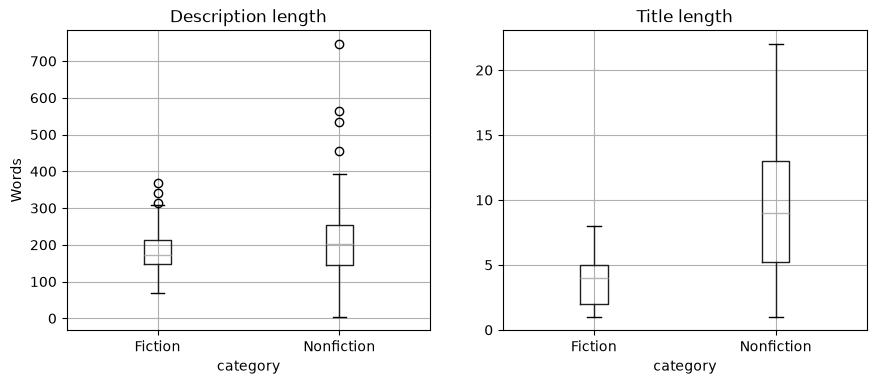

In [32]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 4))   # 1 row, 2 plots side by side

df.boxplot(column="description_words", by="category", ax=axes[0])
df.boxplot(column="title_words", by="category", ax=axes[1])

axes[0].set_title("Description length")
axes[1].set_title("Title length")
axes[0].set_ylabel("Words")
plt.suptitle("")   # removes an automatic extra title pandas adds
plt.show()


This just gives us a visual representation of what we already knew.

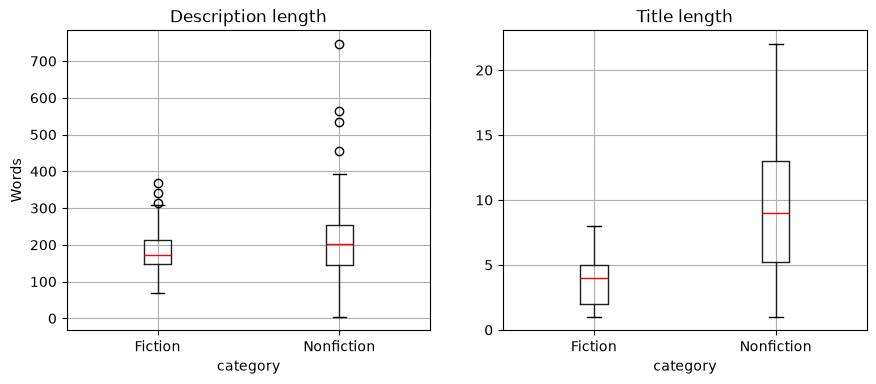

In [33]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 4))   # 1 row, 2 plots side by side

df.boxplot(column="description_words", by="category", medianprops=dict(color="red"), ax=axes[0])
df.boxplot(column="title_words", by="category", medianprops=dict(color="red"), ax=axes[1])

axes[0].set_title("Description length")
axes[1].set_title("Title length")
axes[0].set_ylabel("Words")
axes[0].set_ylabel("Words")
plt.suptitle("")   # removes an automatic extra title pandas adds
plt.show()


Next im going to compare the most frequent words from both categories

In [ ]:
from collections import Counter

fiction_descriptions = df[df["category"] == "Fiction"]["description"]
fiction_word_counts = Counter(" ".join(fiction_descriptions).split())

Counter.most_common(fiction_word_counts, 10)  # Show the 10 most common words in fiction descriptions


[('the', 535),
 ('and', 409),
 ('a', 400),
 ('of', 359),
 ('to', 283),
 ('is', 199),
 ('in', 186),
 ('her', 151),
 ('his', 109),
 ('with', 101)]

In [38]:
def top_words_by_category( category, n=10):
    descriptions = df[df["category"] == category]["description"]
    word_counts = Counter(" ".join(descriptions).split())
    return Counter.most_common(word_counts, n)

pd.DataFrame({
    "Fiction": top_words_by_category("Fiction", 10),
    "Nonfiction": top_words_by_category("Nonfiction", 10)
})

,Fiction,Nonfiction
0,"(the, 535)","(the, 1167)"
1,"(and, 409)","(of, 899)"
2,"(a, 400)","(and, 884)"
3,"(of, 359)","(to, 594)"
4,"(to, 283)","(a, 589)"
5,"(is, 199)","(in, 374)"
6,"(in, 186)","(that, 225)"
7,"(her, 151)","(is, 218)"
8,"(his, 109)","(with, 176)"
9,"(with, 101)","(on, 162)"


From the table we can see that most words are filler words and they do not really show us anything. We need to filter them out. I want to keep her and his since they seem to have a correlation with Fiction books

In [49]:
import re

from pygments.lexer import words
def top_words_by_category(category, n=20):
    descriptions = df[df["category"] == category]["description"]
    words = re.findall(r"[a-z'’]+", " ".join(descriptions).lower())
    return Counter(words).most_common(n)

pd.DataFrame({
    "Fiction": top_words_by_category("Fiction", 20),
    "Nonfiction": top_words_by_category("Nonfiction", 20)
})

,Fiction,Nonfiction
0,"(the, 614)","(the, 1299)"
1,"(and, 454)","(and, 959)"
2,"(a, 443)","(of, 910)"
3,"(of, 361)","(a, 638)"
4,"(to, 289)","(to, 610)"
5,"(in, 217)","(in, 476)"
6,"(is, 205)","(that, 242)"
7,"(her, 176)","(is, 231)"
8,"(his, 112)","(with, 196)"
9,"(with, 107)","(on, 176)"


I am going to start by making a word set based on the filler words i find in the table

In [48]:
STOP_WORDS = {
    "the", "and", "a", "of", "to", "in", "is", "that", "with", "on", "for", "from", "as", "this", "it", "but", "by"
}
def top_words_by_category(category, n=20):
    descriptions = df[df["category"] == category]["description"]
    words = re.findall(r"[a-z'’]+", " ".join(descriptions).lower())
    words = [word for word in words if word not in STOP_WORDS]   # <- new
    return Counter(words).most_common(n)

pd.DataFrame({
    "Fiction": top_words_by_category("Fiction", 20),
    "Nonfiction": top_words_by_category("Nonfiction", 20)
})


,Fiction,Nonfiction
0,"(her, 176)","(his, 126)"
1,"(his, 112)","(her, 122)"
2,"(she, 91)","(our, 117)"
3,"(an, 74)","(we, 112)"
4,"(he, 63)","(life, 107)"
5,"(has, 61)","(are, 107)"
6,"(who, 60)","(an, 102)"
7,"(their, 57)","(what, 94)"
8,"(at, 51)","(new, 91)"
9,"(one, 50)","(at, 90)"


The table does not really show us anything now either. Im going to try and make a list based on word rates instead

In [54]:
def word_rates(category):
    descriptions = df[df["category"] == category]["description"]
    words = re.findall(r"[a-z'’]+", " ".join(descriptions).lower())
    words = [word for word in words if word not in STOP_WORDS]
    total = len(words)
    return {word: count / total * 1000 for word, count in Counter(words).items()}

rates = pd.DataFrame({
    "Fiction": word_rates("Fiction"),
    "Nonfiction": word_rates("Nonfiction"),
}).fillna(0)

rates["difference"] = rates["Fiction"] - rates["Nonfiction"]

rates.sort_values("difference", ascending=False).head(20)   # most typical for Fiction
rates.sort_values("difference").head(20)                    # most typical for Nonfiction

,Fiction,Nonfiction,difference
our,0.921447,6.863780,-5.942334
we,1.727713,6.570456,-4.842744
us,0.575904,3.519887,-2.943983
book,1.727713,4.634518,-2.906806
was,1.266989,3.989206,-2.722217
your,0.921447,3.637217,-2.715770
or,1.958074,4.575854,-2.617779
how,2.073255,4.341194,-2.267939
i,0.806266,3.050569,-2.244303
you,2.879521,5.103837,-2.224316


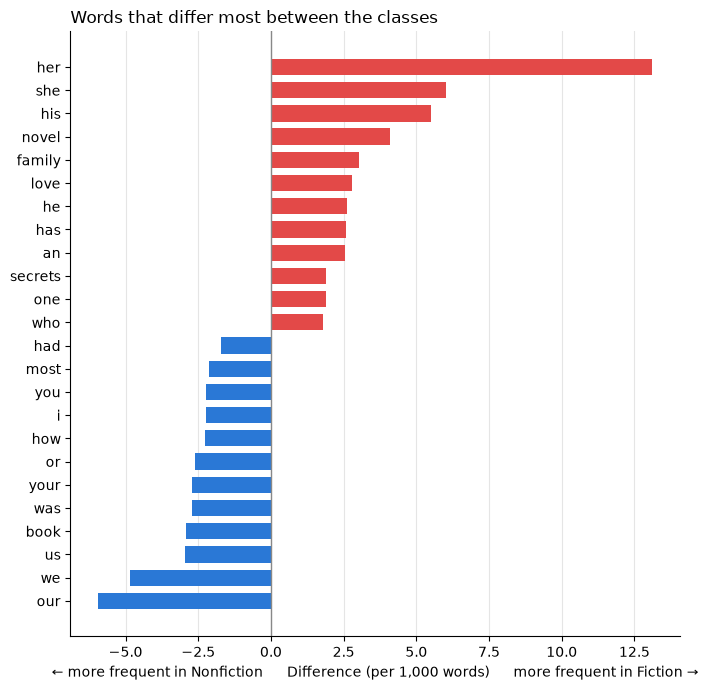

,Fiction,Nonfiction,difference
our,0.92,6.86,-5.94
we,1.73,6.57,-4.84
us,0.58,3.52,-2.94
book,1.73,4.63,-2.91
was,1.27,3.99,-2.72
your,0.92,3.64,-2.72
or,1.96,4.58,-2.62
how,2.07,4.34,-2.27
i,0.81,3.05,-2.24
you,2.88,5.10,-2.22


In [55]:
# Count every word per class (stop words removed), one column per class
def class_words(category):
    descriptions = df[df["category"] == category]["description"]
    words = re.findall(r"[a-z'’]+", " ".join(descriptions).lower())
    return [word for word in words if word not in STOP_WORDS]

counts = pd.DataFrame({
    "Fiction": Counter(class_words("Fiction")),
    "Nonfiction": Counter(class_words("Nonfiction")),
}).fillna(0)  # words that only appear in one class get 0 in the other

# Counts -> frequency per 1,000 words, so the classes can be compared fairly
rates = counts / counts.sum() * 1000
rates["difference"] = rates["Fiction"] - rates["Nonfiction"]  # > 0 = more Fiction, < 0 = more Nonfiction

# Ignore rare words: a word seen only a few times can't tell us much
rates = rates[counts.sum(axis=1) >= 10]

# The 12 most Fiction-typical and the 12 most Nonfiction-typical words
N = 12
top = pd.concat([rates.nlargest(N, "difference"), rates.nsmallest(N, "difference")])
top = top.sort_values("difference")

# Horizontal bar chart: bars to the right = Fiction, to the left = Nonfiction
FICTION_COLOR, NONFICTION_COLOR = "#e34948", "#2a78d6"
colors = [FICTION_COLOR if d > 0 else NONFICTION_COLOR for d in top["difference"]]

fig, ax = plt.subplots(figsize=(7, 7))
ax.barh(top.index, top["difference"], color=colors, height=0.7)
ax.axvline(0, color="#888888", linewidth=1)  # the zero line in the middle
ax.set_title("Words that differ most between the classes", loc="left")
ax.set_xlabel("← more frequent in Nonfiction      Difference (per 1,000 words)      more frequent in Fiction →")
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)       # remove box lines that add nothing
ax.grid(axis="x", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)                       # grid lines behind the bars
plt.tight_layout()
plt.show()

top.round(2)  # the numbers behind the chart

### Image exploration

In [61]:
from PIL import Image, ImageStat

with Image.open("../data/raw/" + df.loc[0, "image_path"]) as img:
    stat = ImageStat.Stat(img.convert("RGB")) # Convert to RGB to ensure we have 3 channels
    stat_gray = ImageStat.Stat(img.convert("L")) # Convert to grayscale to get the mean brightness
    print(f"Mean RGB values: {stat.mean}")# Show the mean RGB values of the image
    print(f"Mean brightness: {stat_gray.mean}")# Show the mean brightness of the image

Mean RGB values: [237.1269425179264, 230.01999529798988, 167.9161631597508]
Mean brightness: [225.0472552015987]


I am going to make a function that uses these values

In [62]:
from PIL import Image, ImageStat

def image_stats(path):
    """Compute simple colour statistics for one cover image."""
    with Image.open("../data/raw/" + path) as img:
        rgb = img.convert("RGB")

        # Average of each colour channel, 0 (none) to 255 (full)
        red, green, blue = ImageStat.Stat(rgb).mean

        # Grayscale ("L") has one channel: how light each pixel is
        brightness = ImageStat.Stat(rgb.convert("L")).mean[0]

        # HSV = hue, saturation, value. Channel 1 is saturation:
        # 0 = grey/washed out, 255 = strong, vivid colours
        saturation = ImageStat.Stat(rgb.convert("HSV")).mean[1]

    return pd.Series({
        "brightness": brightness,
        "red": red,
        "green": green,
        "blue": blue,
        "saturation": saturation,
    })

In [63]:
image_features = df["image_path"].apply(image_stats)
df = pd.concat([df, image_features], axis=1)   # add the new columns next to the existing ones

df.groupby("category")[["brightness", "red", "green", "blue", "saturation"]].median()

,brightness,red,green,blue,saturation
category,,,,,
Fiction,145.725777,148.822462,141.735225,131.843979,92.369705
Nonfiction,151.401968,165.084811,146.155793,145.199683,69.210122


Looking at the table it seems like the only significant difference is in saturation. Lets look at the quartiles and visualise the data next.

In [64]:
IMAGE_FEATURES = ["brightness", "red", "green", "blue", "saturation"]

df.groupby("category")[IMAGE_FEATURES].quantile([0.25, 0.5, 0.75]).round(1)

brightness    red  green   blue  saturation
category                                                    
Fiction    0.25        91.6   94.4   92.7   75.9        49.7
           0.50       145.7  148.8  141.7  131.8        92.4
           0.75       181.3  192.7  184.0  174.9       121.8
Nonfiction 0.25        99.8  109.4   89.0   84.4        36.3
           0.50       151.4  165.1  146.2  145.2        69.2
           0.75       192.6  213.5  196.0  189.3       122.5

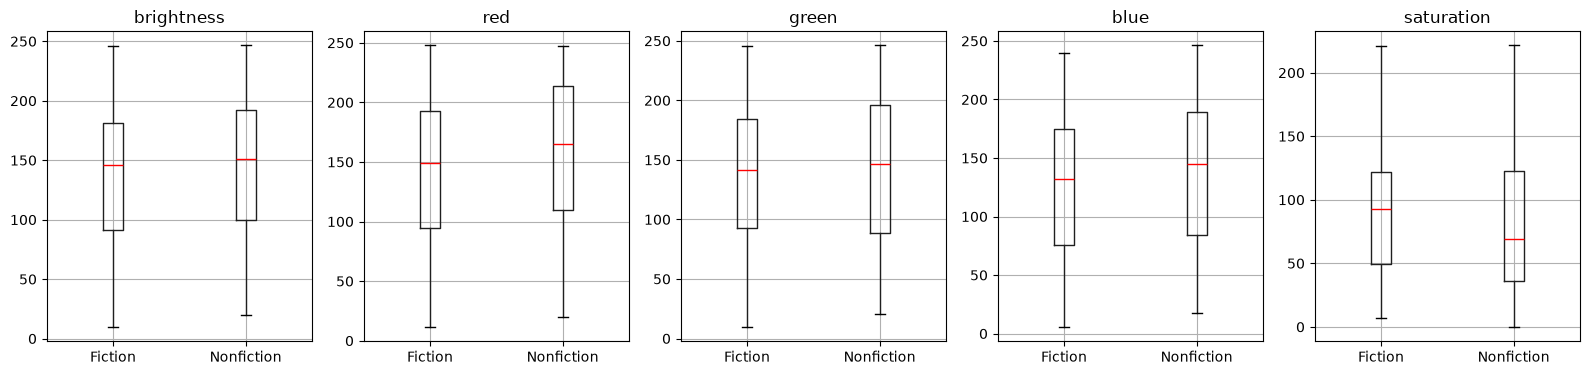

In [65]:
fig, axes = plt.subplots(1, 5, figsize=(16, 4))   # 1 row, 5 plots side by side

for ax, feature in zip(axes, IMAGE_FEATURES):
    df.boxplot(column=feature, by="category", medianprops=dict(color="red"), ax=ax)
    ax.set_title(feature)
    ax.set_xlabel("")

plt.suptitle("")
plt.tight_layout()
plt.show()


Saturation has the biggest difference but there is still very much overlap.